# Getting started with `fastpiclef`

**Fast Picard–Lefschetz** wave-optics / Fresnel-integral solver.
It computes the amplification factor
$$F(\omega,\boldsymbol\beta) = \Big(\tfrac{\omega}{2\pi i}\Big)^{d/2}\int_{\mathbb R^d} e^{\,i\omega\phi(\mathbf x;\boldsymbol\beta)}\,d^d x,$$
normalised so free space gives $F=1$.

**Install (editable, from the repo):**
```bash
pixi run -e notebook build     # maturin develop --release into the notebook env
pixi run -e notebook lab       # launch JupyterLab
```

The wrapper exposes a *parametrised phase library* and a choice of solver method
(`slice`, `thimble`, `polar`, `mesh`, `auto`) — not arbitrary Python phase callbacks, which
would forfeit the performance the Rust core is built for.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import fastpiclef as fpl
print('fastpiclef', [c for c in dir(fpl) if c[0].isupper()])

fastpiclef ['AiryPhase', 'CISComp', 'CustomRationalLens', 'FieldImage', 'LensField', 'MapResult', 'NFWComp', 'PointComp', 'PointMass', 'PointMassField', 'RationalLens', 'RationalLens2D', 'Result', 'SISComp', 'SimGLens', 'SweepResult']


## 1. Trust anchor: the Airy integral

$\int_{\mathbb R} e^{\,i\omega(x^3/3 - yx)}\,dx = 2\pi\,\omega^{-1/3}\,\mathrm{Ai}(-\omega^{2/3}y)$ —
an exact closed form. The solver should hit it to machine precision, through the caustic ($y=0$) too.

In [2]:
from scipy.special import airy
print(f"{'y':>5}{'omega':>7}{'|integral|':>16}{'rel. err vs Ai':>18}")
for y in (-1.0, 0.0, 1.0):
    for omega in (1.0, 4.0):
        r = fpl.AiryPhase(y=y).solve(omega=omega)
        exact = 2*np.pi*omega**(-1/3)*airy(-(omega**(2/3))*y)[0]
        print(f'{y:5.1f}{omega:7.1f}{abs(r.integral):16.10f}{abs(r.integral-exact)/abs(exact):18.2e}')

    y  omega      |integral|    rel. err vs Ai
 -1.0    1.0    0.8500673223          6.40e-15
 -1.0    4.0    0.0602143816          8.16e-14
  0.0    1.0    2.2307070518          2.37e-12
  0.0    4.0    1.4052573854          1.63e-13
  1.0    1.0    3.3650282730          2.90e-15
  1.0    4.0    0.4976881587          7.05e-16


## 2. See the deformation: Lefschetz thimbles

The method replaces the wildly oscillating real-axis integral with an equivalent one along
*constant-phase contours* (thimbles) through the images, where the integrand decays instead of
oscillating. Here is a converging lens with three real images and a complex pair.

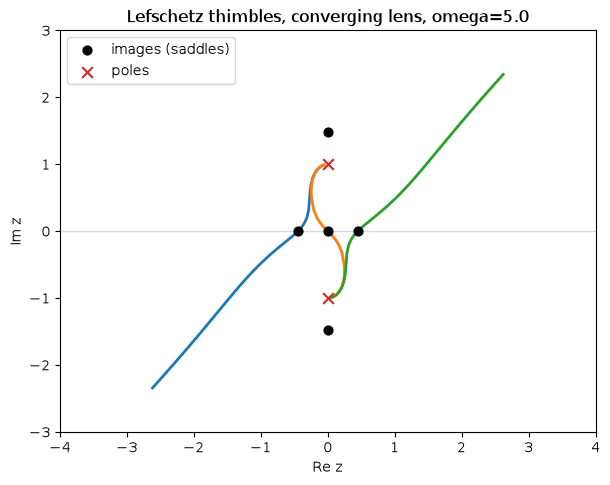

In [3]:
lens = fpl.RationalLens(beta=0.0, kappa=-0.72)   # phi = z^2/2 - kappa/(1+z^2)
omega = 5.0
pieces = lens.thimble(omega)
saddles = np.array(lens.saddles())
poles = np.array([1j, -1j])   # rational lens: psi = 1/(1+z^2)

fig, ax = plt.subplots(figsize=(6.2, 5))
ax.axhline(0, color='0.85', lw=1, zorder=0)
for p in pieces:
    p = np.array(p)
    ax.plot(p.real, p.imag, lw=2)
ax.scatter(saddles.real, saddles.imag, c='k', s=40, zorder=5, label='images (saddles)')
ax.scatter(poles.real, poles.imag, marker='x', c='C3', s=60, zorder=5, label='poles')
ax.set(xlabel='Re z', ylabel='Im z', title=f'Lefschetz thimbles, converging lens, omega={omega}')
ax.set_xlim(-4, 4); ax.set_ylim(-3, 3); ax.set_aspect('equal'); ax.legend()
plt.tight_layout(); plt.show()

## 3. The wave → geometric-optics transition

The magnification $|F|^2$ interpolates between smooth diffraction (small $\omega$, wave optics)
and the interference of the discrete geometric images (large $\omega$). The dashed line is the
geometric-optics total magnification $\sum_j |\mu_j| = \sum_j 1/|\phi''(x_j)|$ over the real
images: at small $\omega$ diffraction suppresses $|F|^2$ below it; at large $\omega$ the image
interference oscillates around it.

*(Very small $\omega$ needs a wider contour window — an automatic $\omega$-scaling is planned —
which is why the leftmost points are less reliable.)*

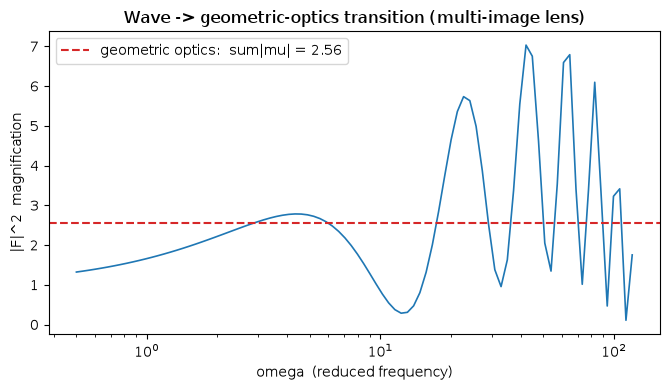

In [4]:
lens = fpl.RationalLens(beta=0.2, kappa=-1.2)
omegas = np.geomspace(0.5, 120.0, 90)
amps, _ = lens.sweep(list(omegas))
magn = np.abs(np.array(amps))**2

kappa = -1.2
d2phi = lambda x: 1.0 + 2*kappa*(1 - 3*x*x)/(1 + x*x)**3   # phi'' for this lens
images_1d = [z.real for z in lens.saddles() if abs(z.imag) < 1e-9]
mu_tot = sum(1.0/abs(d2phi(x)) for x in images_1d)

fig, ax = plt.subplots(figsize=(6.8, 4))
ax.plot(omegas, magn, lw=1.2)
ax.axhline(mu_tot, ls='--', color='C3', label=f'geometric optics:  sum|mu| = {mu_tot:.2f}')
ax.set_xscale('log')
ax.set(xlabel='omega  (reduced frequency)', ylabel='|F|^2  magnification',
       title='Wave -> geometric-optics transition (multi-image lens)')
ax.legend(); plt.tight_layout(); plt.show()

## 4. Frontier: a field of 40 point-mass lenses

A random field of microlenses — the stellar-field problem. It is genuinely 2D and **not**
axisymmetric, so the *axisymmetric* polar solver does not apply; it runs on the exact
Cartesian-slice solver (`method='slice'`, the default for `PointMassField`).

* The solver is **validated** against the point-mass Nakamura–Deguchi closed form
  ($\sim\!10^{-15}$, full complex value) and cross-checked here by two outer contours and by
  transposed slicing — both agree to $\sim\!10^{-15}$.
* Cost is seconds per evaluation (40 masses at $\omega=2$: $\sim\!13$ s threaded), not
  milliseconds — the price of never deciding anything (real core + rotated tails) — but no
  longer the divergent mesh. *Honest correction:* the old mesh-flow value for this field
  ($|F|^2\approx1.55$) was wrong by $\sim\!11\%$; agreement under mesh refinement was never a
  truth check.


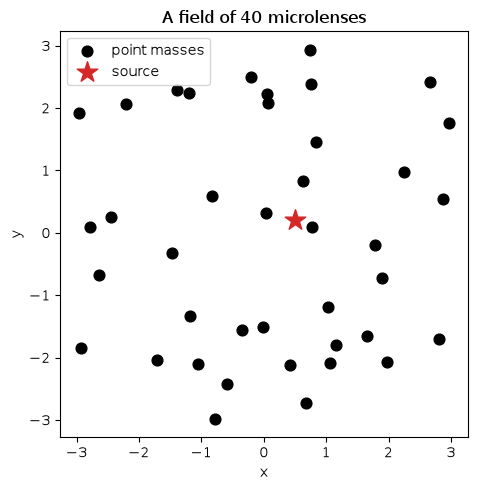

In [5]:
rng = np.random.default_rng(7)
pos = rng.uniform(-3.0, 3.0, size=(40, 2))
masses = np.full(40, 0.05)
lenses = [(float(x), float(y), float(m)) for (x, y), m in zip(pos, masses)]
beta = (0.5, 0.2)
field = fpl.PointMassField(lenses, beta=beta)

fig, ax = plt.subplots(figsize=(5.2, 5))
ax.scatter(pos[:, 0], pos[:, 1], s=60, c='k', label='point masses')
ax.scatter([beta[0]], [beta[1]], marker='*', s=240, c='C3', zorder=5, label='source')
ax.set(xlabel='x', ylabel='y', title='A field of 40 microlenses'); ax.set_aspect('equal'); ax.legend()
plt.tight_layout(); plt.show()

In [6]:
# One amplification evaluation on the exact 2D slice solver (~13 s threaded for
# 40 masses): validated vs the point-mass closed form; two-contour and
# transposed-field checks here agree to ~1e-15.
r = field.solve(omega=2.0, method='slice')
print(r)
print(f'|F| = {abs(r.amplification):.4f}   |F|^2 = {abs(r.amplification)**2:.4f}   '
      f'error = {r.error:.1e}   method = {r.method}')


Result(amplification=-1.176182-0.005134i, integral=0.016128-3.695086i, error=7.13e-13, method='slice', steps=7766)
|F| = 1.1762   |F|^2 = 1.3834   error = 7.1e-13   method = slice


## 5. The lensed image: from points to a field

For a point source, **geometric optics** predicts a set of *discrete images* — the solutions of
the lens equation $\boldsymbol\beta = \mathbf x - \nabla\psi(\mathbf x)$ (equivalently the real
stationary points of $\phi$). Toward the **wave-optics** regime each image is smeared over the
**Fresnel scale $\sim\omega^{-1/2}$**; near caustics the blurred images overlap into extended
structure — a *field* rather than points.

Below: the geometric images from the library's verified finder (left), then the same images
broadened by the Fresnel scale at two frequencies. The finder (`field.images_detailed()`) is a
multi-start Newton seeded with per-star *companion ladders* — each star's faint second image sits
at $\sim m_j/|\mathbf z_j - \boldsymbol\beta|$ — residual-verified and deduplicated, and it
carries a completeness certificate (index identity + per-star companion), so it reports rather
than hides its failure modes. The broadening is the leading Fresnel-scale picture, complementary
to the full diffraction integral $|F|$ of section 4 — whose $|F|^2$ at moderate $\omega$ sits
near the geometric total magnification $\sum_j|\mu_j|$ printed below.


41 geometric images;  total |mu| (geometric magnification) = 1.497


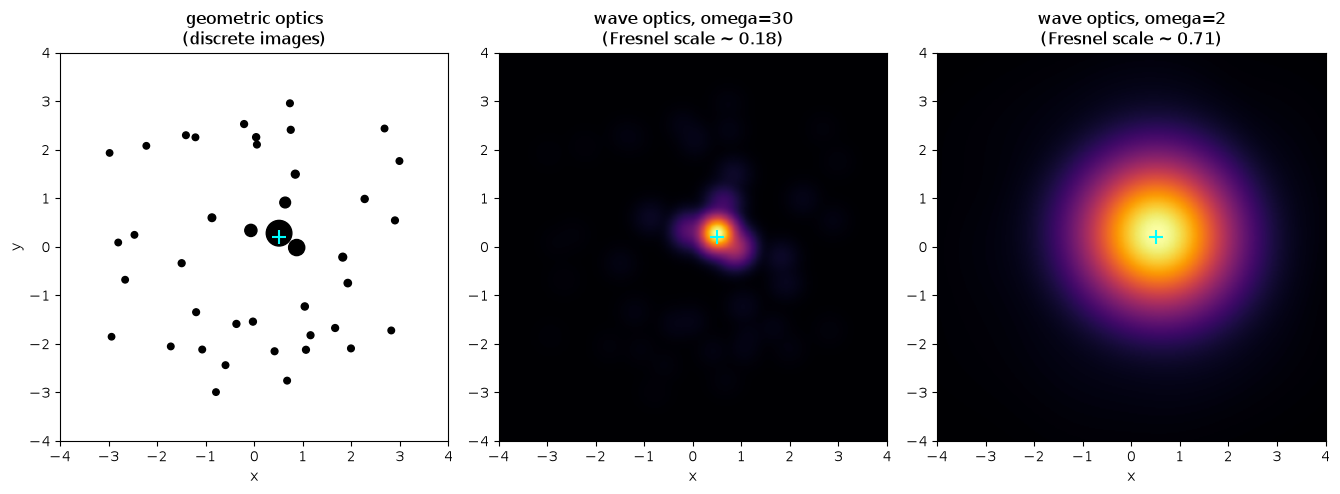

In [7]:
# Geometric images of the field: the library's verified image finder
# (multi-start Newton with per-star companion ladders + completeness certificate).
images = field.images_detailed()
imgs = np.array([[im.x, im.y] for im in images])
mu = np.array([abs(im.mu) for im in images])
print(f'{len(imgs)} geometric images;  total |mu| (geometric magnification) = {mu.sum():.3f}')

gx = np.linspace(-4, 4, 320); X, Y = np.meshgrid(gx, gx)
def intensity(sigma):
    I = np.zeros_like(X)
    for (ix, iy), m in zip(imgs, mu):
        I += m*np.exp(-((X - ix)**2 + (Y - iy)**2)/(2*sigma**2))
    return I

fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.6))
axes[0].scatter(imgs[:, 0], imgs[:, 1], s=20 + 320*np.sqrt(mu/mu.max()), c='k')
axes[0].set_title('geometric optics\n(discrete images)')
for ax, w in zip(axes[1:], (30.0, 2.0)):
    sig = 1.0/np.sqrt(w)
    ax.imshow(intensity(sig)**0.4, extent=[-4, 4, -4, 4], origin='lower', cmap='inferno')
    ax.set_title(f'wave optics, omega={w:g}\n(Fresnel scale ~ {sig:.2f})')
for ax in axes:
    ax.scatter([beta[0]], [beta[1]], marker='+', c='cyan', s=90, zorder=6)
    ax.set_aspect('equal'); ax.set_xlim(-4, 4); ax.set_ylim(-4, 4); ax.set_xlabel('x')
axes[0].set_ylabel('y')
plt.tight_layout(); plt.show()


## 6. Gravitational waves: `F(f)` for a stellar lens in a macro image

The dimensionless frequency is `w = 8 pi G M_Lz f / c^3 = 1.2379e-4 (M_Lz/M_sun)(f/Hz)`
(lengths in units of the Einstein radius of the reference mass). A 10 M_sun lens in the
LIGO band spans `w ~ 0.01-1` — the regime this solver was built for. Here one stellar
microlens rides on a macro image (`kappa`, `gamma1`); both a type-I (minimum) and a
type-II (saddle) macro image are exact (a real-box FFT method cannot represent the
type-II saddle directions). The batched `sweep` evaluates the whole frequency grid on
one shared contour.

In [8]:
M_lz = 10.0                               # redshifted lens mass [Msun]
f_hz = np.geomspace(10.0, 1000.0, 24)     # LIGO band
w = 1.2379e-4 * M_lz * f_hz

star = fpl.PointComp(0.10, -0.05, 0.05)   # one stellar microlens
typeI = fpl.LensField([star], beta=(0.30, 0.10), kappa=0.30, gamma1=0.20)
typeII = fpl.LensField([star], beta=(0.30, 0.10), kappa=0.50, gamma1=0.70)

swI = typeI.sweep(list(w))
swII = typeII.sweep(list(w))
print(swI)
print(swII)

SweepResult(n=24, method='slice-batch', inner_solves=1720, groups=2)
SweepResult(n=24, method='slice-batch', inner_solves=1880, groups=2)


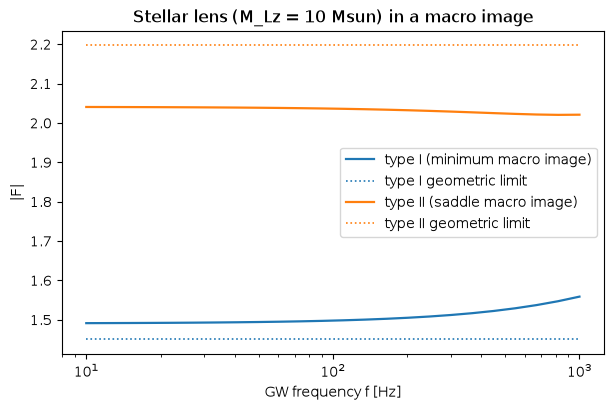

In [9]:
geoI = np.array([complex(typeI.geometric(float(wi)).amplification) for wi in w])
geoII = np.array([complex(typeII.geometric(float(wi)).amplification) for wi in w])

fig, ax = plt.subplots(figsize=(7, 4.2))
ax.plot(f_hz, np.abs(swI.amplification), lw=1.6, label='type I (minimum macro image)')
ax.plot(f_hz, np.abs(geoI), ':', color='C0', lw=1.2, label='type I geometric limit')
ax.plot(f_hz, np.abs(swII.amplification), lw=1.6, label='type II (saddle macro image)')
ax.plot(f_hz, np.abs(geoII), ':', color='C1', lw=1.2, label='type II geometric limit')
ax.set(xscale='log', xlabel='GW frequency f [Hz]', ylabel='|F|',
       title=f'Stellar lens (M_Lz = {M_lz:g} Msun) in a macro image')
ax.legend()
plt.show()

## 7. A halo: NFW plus stars

The same engine carries halo profiles (`NFW`, `SIS`, `CIS`): here a subhalo with two
stellar masses inside a macro image, swept over a frequency grid (a few seconds).

In [10]:
halo = fpl.NFWComp(0.0, 0.0, 0.5, 0.8)   # psi0, scale radius xs
stars = [fpl.PointComp(0.3, -0.2, 0.02), fpl.PointComp(-0.25, 0.35, 0.02)]
halo_field = fpl.LensField([halo, *stars], beta=(0.5, 0.0), kappa=0.2)
w_halo = np.geomspace(0.3, 30.0, 12)
swH = halo_field.sweep(list(w_halo))
print(swH)
print('images:', halo_field.images())

SweepResult(n=12, method='slice-batch', inner_solves=3480, groups=2)
images: [(0.9226698774520702, 0.008639144024427484)]


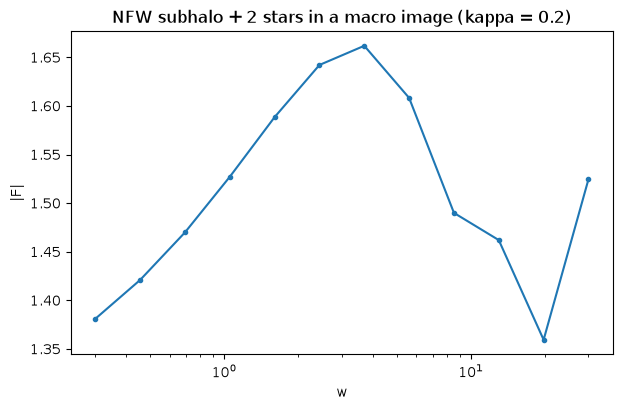

In [11]:
fig, ax = plt.subplots(figsize=(7, 4.2))
ax.plot(w_halo, np.abs(swH.amplification), 'o-', ms=3)
ax.set(xscale='log', xlabel='w', ylabel='|F|',
       title='NFW subhalo + 2 stars in a macro image (kappa = 0.2)')
plt.show()

## 8. Fast paths: the closed form, the hybrid, and when to use which (P4)

The exact engines are the default, but three validated shortcuts cover the common science
regimes on top of them:

| route | call | regime | cost |
|---|---|---|---|
| closed form | `fpl.point_mass_nd(omega, y)` | isolated point mass, `omega*y <~ 10` (the compound parameter) | ~2 µs |
| 1D polar | `fpl.PointMass(y).solve(omega, method="polar")` | isolated / axisymmetric lens, high omega | 30-300 ms (omega = 10-100) |
| hybrid | `field.hybrid(omega, tol)` | any field, when the geometric+correction budget fits `tol` | milliseconds + images |

The hybrid branch is not a heuristic: it is geometric optics **plus the stationary-phase
next-order correction** ($F = \sum_j |\mu_j|^{1/2} e^{i\omega\varphi_j - i\pi n_j}
(1 + C_j/(i\omega))$), and it is taken *only* when its reported budget
$3\sum_j |G_{0,j}||C_j|/\omega$ fits `tol`; otherwise the call stays on the exact RC engine.
`.method` always tells you which path ran.


In [12]:
# 8a. Nakamura-Deguchi closed form: ~2 µs, reference grade while w*y <~ 10 (the compound parameter; at fixed |z| the error grows with w - see results/nd_band.csv).
# It carries the standard Fermat-offset phase -> compare |F| against a solver.
# Reference policy: the exact 2D RC at low omega (the polar 1D path is only
# 1e-6..1e-2 accurate there), the polar path at high omega (fast and exact).
pm1 = fpl.PointMass(1.0)
pmf1 = fpl.PointMassField([(0.0, 0.0, 1.0)], beta=(1.0, 0.0))
print(f"{'omega':>6} {'|z|':>6} {'|F| ND':>14} {'|F| ref':>14} {'rel diff':>9} {'ND budget':>10}  reference")
for w in [0.3, 1.0, 3.0, 10.0, 30.0]:
    nd = fpl.point_mass_nd(omega=w, y=1.0)
    if w <= 3.0:
        ex, ref = pmf1.solve(omega=w), '2D exact RC'
    else:
        ex, ref = pm1.solve(omega=w, method="polar"), 'polar'
    a, b = abs(nd.amplification), abs(ex.amplification)
    print(f"{w:6.1f} {0.5*w:6.2f} {a:14.10f} {b:14.10f} {abs(a-b)/b:9.1e} {nd.error*w/(2*np.pi):10.1e}  {ref}")
# Beyond the valid band the estimate grows honestly -> route to a solver there.
nd = fpl.point_mass_nd(omega=100.0, y=1.0)
print(f"omega=100 (|z|=50): ND budget = {nd.error*100/(2*np.pi):.1e}  -> use the polar path instead")


 omega    |z|         |F| ND        |F| ref  rel diff  ND budget  reference
   0.3   0.15   1.2148857906   1.2148857906   9.3e-15    2.8e-14  2D exact RC
   1.0   0.50   1.3932452420   1.3932452420   3.8e-15    3.9e-14  2D exact RC
   3.0   1.50   1.1202804051   1.1202804051   5.0e-15    1.1e-13  2D exact RC
  10.0   5.00   1.4738687389   1.4738687389   5.4e-13    1.4e-10  polar


  30.0  15.00   0.9862676300   0.9870922833   8.4e-04    4.0e-01  polar
omega=100 (|z|=50): ND budget = 5.1e+32  -> use the polar path instead


In [13]:
# 8b. The hybrid switch: a tight tol stays on the exact RC engine; a loose tol takes the
# corrected geometric branch, which must beat the bare geometric sum (external closed form
# |F| = 1.762705414788 at omega=100, y=0.5).
field1 = fpl.PointMassField([(0.0, 0.0, 1.0)], beta=(0.5, 0.0))
for tol in [1e-12, 1e-3]:
    r = field1.hybrid(omega=100.0, tol=tol)
    print(f"tol={tol:8.0e}: method={r.method:>22s}  |F| = {abs(r.amplification):.12f}  budget = {r.error:.2e}")
fnd = 1.762705414788
hyb = abs(field1.hybrid(omega=100.0, tol=1e-3).amplification)
geo = abs(field1.geometric(omega=100.0).amplification)
print(f"hybrid (corr.)   : rel err vs closed form = {abs(hyb-fnd)/fnd:.2e}")
print(f"geometric (bare) : rel err vs closed form = {abs(geo-fnd)/fnd:.2e}")
gc = field1.geometric_corrected(omega=100.0)   # the asymptotic form alone, with its budget
print(f"geometric_corrected: |F| = {abs(gc.amplification):.12f}, budget = {gc.error:.2e} (integral units)")


tol=   1e-12: method=                 slice  |F| = 1.762705414788  budget = 1.49e-13
tol=   1e-03: method=  geometric+correction  |F| = 1.762757297245  budget = 8.01e-04
hybrid (corr.)   : rel err vs closed form = 2.94e-05
geometric (bare) : rel err vs closed form = 1.27e-03
geometric_corrected: |F| = 1.762757297245, budget = 8.01e-04 (integral units)


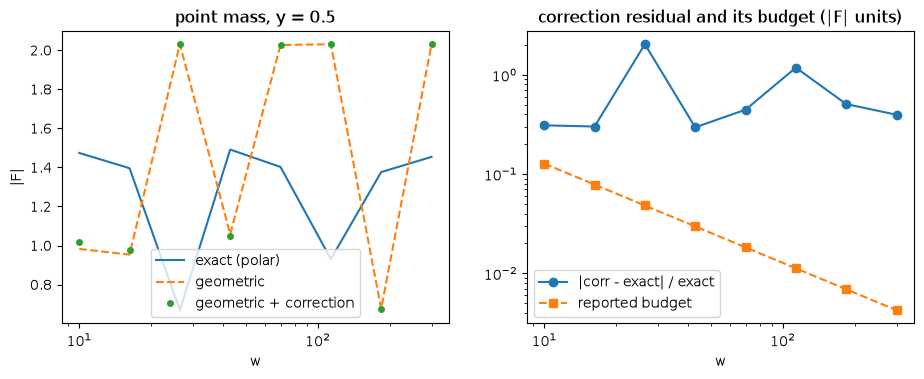

In [14]:
# 8c. The corrected geometric sum tracks the exact result, and the budget tracks the residual.
ws = np.geomspace(10.0, 300.0, 8)
exact, geo, corr, bud = [], [], [], []
for w in ws:
    ex = pm1.solve(omega=float(w), method="polar")        # independent exact reference
    g = field1.geometric_corrected(float(w))
    exact.append(abs(ex.amplification))
    corr.append(abs(g.amplification))
    bud.append(g.error * w / (2 * np.pi))                 # budget in |F| units
    geo.append(abs(field1.geometric(float(w)).amplification))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(ws, exact, '-', label='exact (polar)')
ax[0].plot(ws, geo, '--', label='geometric')
ax[0].plot(ws, corr, 'o', ms=4, label='geometric + correction')
ax[0].set(xscale='log', xlabel='w', ylabel='|F|', title='point mass, y = 0.5')
ax[0].legend()
ax[1].loglog(ws, [abs(c-e)/e for c, e in zip(corr, exact)], 'o-', label='|corr - exact| / exact')
ax[1].loglog(ws, bud, 's--', label='reported budget')
ax[1].set(xlabel='w', title='correction residual and its budget (|F| units)')
ax[1].legend()
plt.show()


### Guidance

* **Isolated point mass**: `point_mass_nd` while `omega*y <= ~10` (microseconds; the accuracy driver is the compound `omega*y`); above that the
  polar path (fast for `omega >~ 10`), and the exact slice engine at low `omega`.
* **Fields**: the exact slice engine is the default; use `.hybrid(omega, tol)` when `omega` is
  high enough that the budget fits your tolerance.  A caustic always falls back to the exact
  engine, and the fast branch uses the verified, certificate-checked image finder (a failed
  certificate raises instead of silently missing a companion image).
* The 2D exact engine stays the reference everywhere: validated at ~1e-15 against independent
  closed forms over `omega` in [0.3, 1000] (catalogue: `docs/error_budget.md`).


## What's next

* **Contour warm-starting** on grid protocols — the main remaining performance lever (P-LPI
  amortises across grids; our solvers currently compute every point independently).
* A **convergence-order study** and the remaining evaluation-program items.
* The **thimble routing** at very high $\omega$ (the reserved lever beyond the slice solver's
  ~linear cost growth).
* **glworia** (a JAX/GPU axisymmetric competitor) on the single-mass regime.
* A true wave-optics magnification map $|F(\omega,\boldsymbol\beta)|^2$ over source position —
  closer now that the field solver is exact, still gated on per-point cost.

See the project journal for the full roadmap.
